# Lab 2: Geometric Transformations

**This notebook demonstrates the image-processing topics covered in Lecture 2 - Geometry and Transformations**
- Linear transformations: **scaling, rotation**
- Why **translation is not linear** in ordinary 2D coordinates
- **Affine transformations**: linear transformations + translation
- **Projective transformation / Homography**

In [ ]:
# Install/import required libraries
# If OpenCV is already installed, the pip line can be skipped.

# !pip -q install opencv-python matplotlib numpy

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
print("OpenCV:", cv2.__version__)

OpenCV: 4.14.0


# Part 1 — 2D Points and Linear Transformations

A 2D point is represented as:

\[
p = \begin{bmatrix}x\\y\end{bmatrix}
\]

A linear transformation uses a 2×2 matrix:

\[
p' = Ap
\]

A key property is:

\[
T(0,0)=(0,0)
\]

So a purely linear 2D transformation keeps the origin fixed.

In [2]:
# Create a simple set of 2D points
points = np.array([
    [1, 1],
    [3, 1],
    [3, 3],
    [1, 3]
], dtype=float).T   # shape: (2, N)

print("Points:")
print(points.T)

Points:
[[1. 1.]
 [3. 1.]
 [3. 3.]
 [1. 3.]]


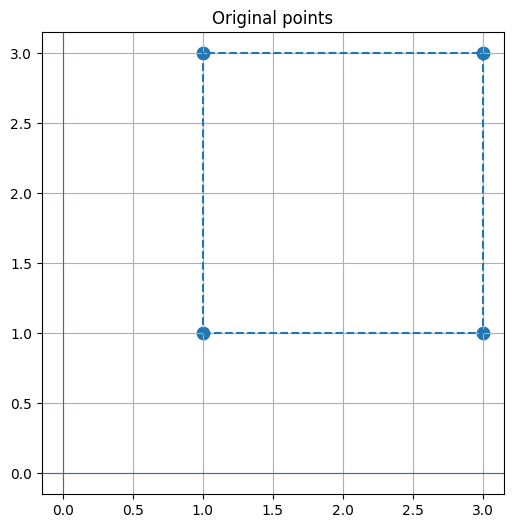

In [3]:
def plot_points(points, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(points[0], points[1], s=80)
    ax.plot(np.r_[points[0], points[0, 0]],
            np.r_[points[1], points[1, 0]], '--')
    ax.axhline(0, linewidth=0.8)
    ax.axvline(0, linewidth=0.8)
    ax.set_aspect('equal')
    ax.grid(True)
    ax.set_title(title)
    return ax

plot_points(points, "Original points")
plt.show()

## 1.1 Uniform scaling

For scale factor \(s\):

\[
A =
\begin{bmatrix}
s & 0\\
0 & s
\end{bmatrix}
\]

Every coordinate is multiplied by the same factor.

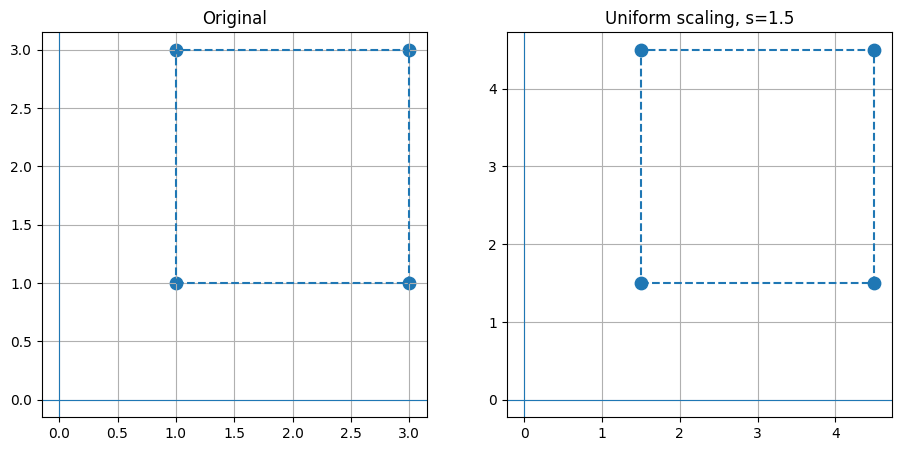

Scaling matrix:
 [[1.5 0. ]
 [0.  1.5]]


In [4]:
s = 1.5

S = np.array([
    [s, 0],
    [0, s]
], dtype=float)

scaled_points = S @ points

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_points(points, "Original", axes[0])
plot_points(scaled_points, f"Uniform scaling, s={s}", axes[1])
plt.show()

print("Scaling matrix:\n", S)

## 1.2 Rotation

For rotation by angle \(\theta\) about the origin:

\[
R =
\begin{bmatrix}
\cos\theta & -\sin\theta\\
\sin\theta & \cos\theta
\end{bmatrix}
\]

The inverse rotation uses \(-\theta\).

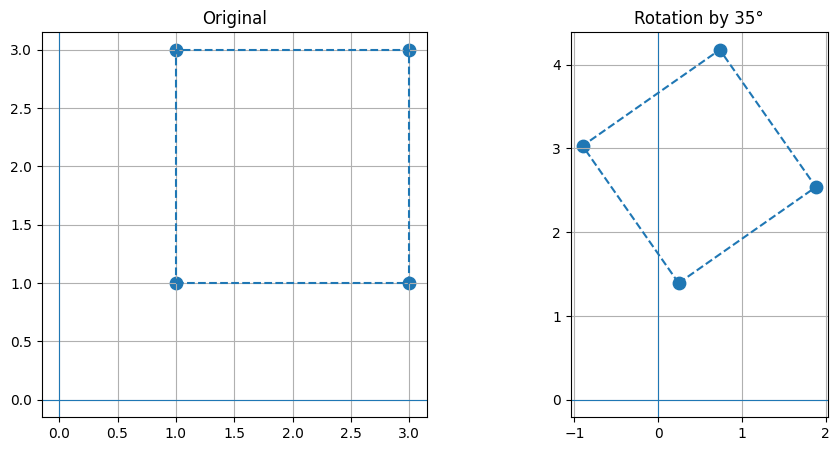

Rotation matrix:
 [[ 0.819 -0.574]
 [ 0.574  0.819]]


In [5]:
theta_deg = 35
theta = np.deg2rad(theta_deg)

R = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta),  np.cos(theta)]
])

rotated_points = R @ points

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_points(points, "Original", axes[0])
plot_points(rotated_points, f"Rotation by {theta_deg}°", axes[1])
plt.show()

print("Rotation matrix:\n", R)

# Part 2 — Why Translation Is Not a 2×2 Linear Transformation

Translation is:

- x' = x+t_x,
- y'=y+t_y

A 2×2 matrix multiplication cannot add the constants \(t_x,t_y\).

For example, translating by \((2,1)\):

\[
\begin{bmatrix}x'\\y'\end{bmatrix}
=
\begin{bmatrix}x\\y\end{bmatrix}
+
\begin{bmatrix}2\\1\end{bmatrix}
\]

Therefore, translation is **not a linear transformation in ordinary 2D coordinates**.

The lecture introduces **homogeneous coordinates** to handle this.

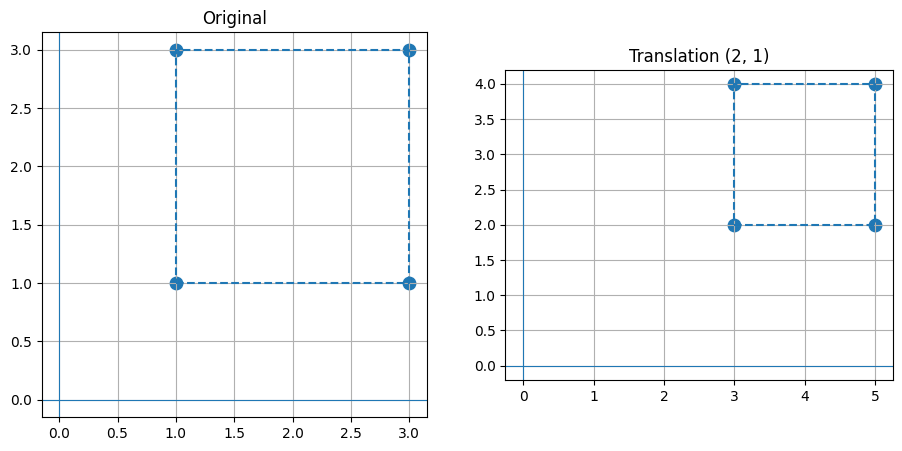

Original origin -> [0 0]
Translated origin -> [2 1]


In [7]:
# Translation in ordinary Cartesian coordinates

tx, ty = 2, 1
translated_points = points + np.array([[tx], [ty]])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_points(points, "Original", axes[0])
plot_points(translated_points, f"Translation ({tx}, {ty})", axes[1])
plt.show()

print("Original origin ->", np.array([0, 0]))
print("Translated origin ->", np.array([tx, ty]))

# Part 3 — Homogeneous Coordinates and Affine Transformations

Convert:

\[
(x,y) \rightarrow (x,y,1)
\]

Then an affine transformation can be written as one 3×3 matrix:

\[
\begin{bmatrix}
x'\\y'\\1
\end{bmatrix}
=
\begin{bmatrix}
a&b&t_x\\
c&d&t_y\\
0&0&1
\end{bmatrix}
\begin{bmatrix}
x\\y\\1
\end{bmatrix}
\]

The upper-left 2×2 block handles the linear part; \(t_x,t_y\) handle translation.

Thus, **affine transformations = linear transformations + translation**.

In [8]:
def to_homogeneous(points_2d):
    return np.vstack([points_2d, np.ones((1, points_2d.shape[1]))])

def from_homogeneous(points_h):
    return points_h[:2] / points_h[2:3]

points_h = to_homogeneous(points)
print("Homogeneous points:\n", points_h)

Homogeneous points:
 [[1. 3. 3. 1.]
 [1. 1. 3. 3.]
 [1. 1. 1. 1.]]


Affine translation matrix:
 [[1. 0. 2.]
 [0. 1. 1.]
 [0. 0. 1.]]

Translated points:
 [[3. 2.]
 [5. 2.]
 [5. 4.]
 [3. 4.]]


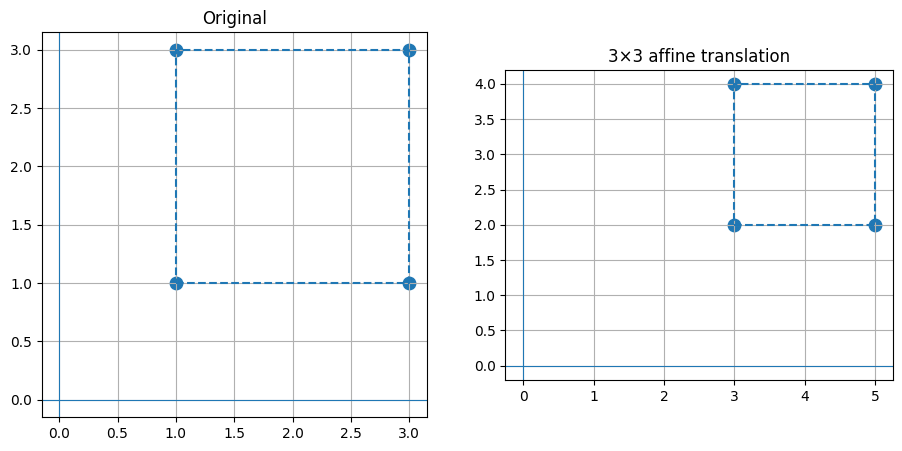

In [9]:
# 3x3 affine translation matrix
T = np.array([
    [1, 0, tx],
    [0, 1, ty],
    [0, 0, 1]
], dtype=float)

translated_h = T @ points_h
translated_from_h = from_homogeneous(translated_h)

print("Affine translation matrix:\n", T)
print("\nTranslated points:\n", translated_from_h.T)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_points(points, "Original", axes[0])
plot_points(translated_from_h, "3×3 affine translation", axes[1])
plt.show()

## 3.1 Combining affine transformations

Because affine transformations are closed under composition, we can combine operations into a single 3×3 matrix.

The following example combines:
- scaling
- rotation
- translation

Combined affine matrix:
 [[ 1.088 -0.507  2.   ]
 [ 0.507  1.088  1.   ]
 [ 0.     0.     1.   ]]


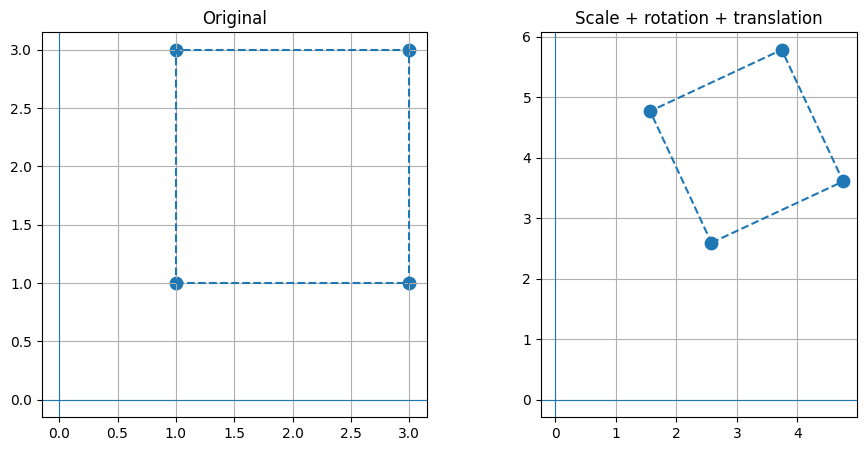

In [10]:
scale = 1.2
angle = np.deg2rad(25)
tx, ty = 2.0, 1.0

A_scale = np.array([
    [scale, 0, 0],
    [0, scale, 0],
    [0, 0, 1]
], dtype=float)

A_rotate = np.array([
    [np.cos(angle), -np.sin(angle), 0],
    [np.sin(angle),  np.cos(angle), 0],
    [0, 0, 1]
], dtype=float)

A_translate = np.array([
    [1, 0, tx],
    [0, 1, ty],
    [0, 0, 1]
], dtype=float)

A = A_translate @ A_rotate @ A_scale

combined = from_homogeneous(A @ points_h)

print("Combined affine matrix:\n", A)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_points(points, "Original", axes[0])
plot_points(combined, "Scale + rotation + translation", axes[1])
plt.show()

# Part 4 — Affine Transformation of an Image

Now we move from individual points to an actual image.

An affine transformation maps the image using a 2×3 matrix:

\[
\begin{bmatrix}
a&b&t_x\\
c&d&t_y
\end{bmatrix}
\]

OpenCV uses `cv2.warpAffine()` to perform the image warp.

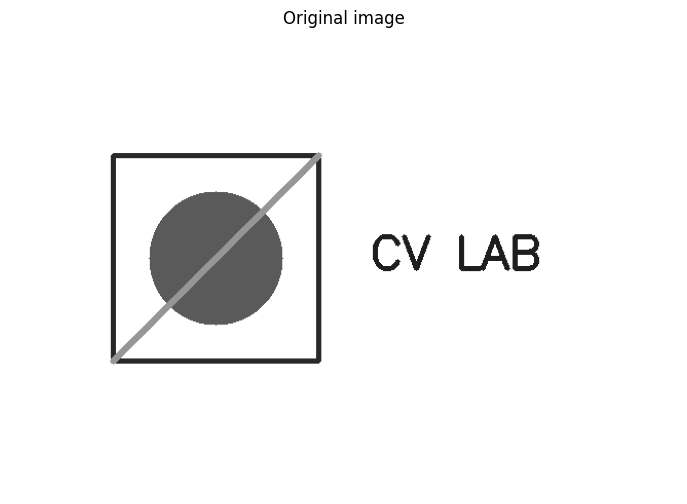

In [11]:
# Create a simple synthetic image
img = np.ones((450, 650, 3), dtype=np.uint8) * 255

cv2.rectangle(img, (100, 120), (300, 320), (40, 40, 40), 4)
cv2.circle(img, (200, 220), 65, (90, 90, 90), -1)
cv2.line(img, (100, 320), (300, 120), (150, 150, 150), 5)
cv2.putText(img, "CV LAB", (350, 230),
            cv2.FONT_HERSHEY_SIMPLEX, 1.5, (30, 30, 30), 3)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Original image")
plt.show()

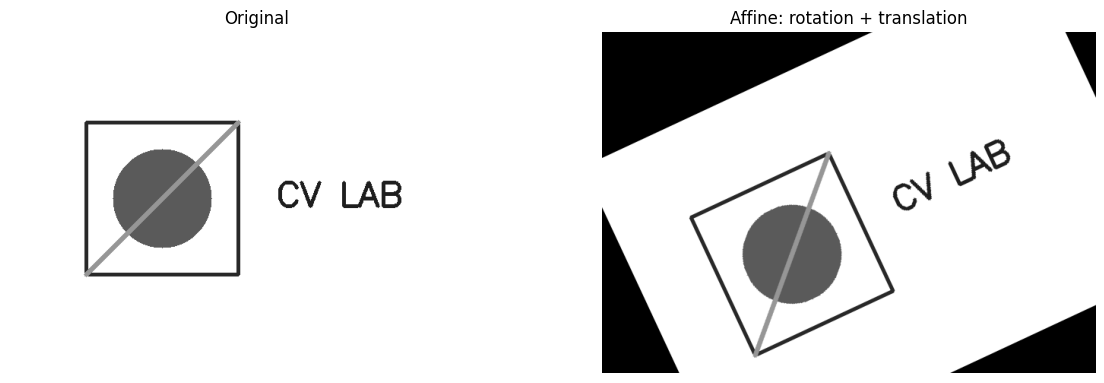

Affine matrix:
 [[  0.906   0.423 -24.639]
 [ -0.423   0.906 178.432]]


In [12]:
# Affine transformation: rotation + translation
h, w = img.shape[:2]
center = (w // 2, h // 2)

M = cv2.getRotationMatrix2D(center, 25, 1.0)
M[:, 2] += [40, 20]  # additional translation

affine_img = cv2.warpAffine(img, M, (w, h))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(affine_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Affine: rotation + translation")
axes[1].axis("off")

plt.show()

print("Affine matrix:\n", M)

# Part 5 — Homography / Projective Transformation

A **homography is a projective transformation**.

It is useful when the same planar surface is viewed from different camera viewpoints, for example:
- image stitching
- perspective correction
- straightening a document
- tracking a flat surface
- mapping a planar object between views

A homography is represented by a 3×3 matrix:

\[
H =
\begin{bmatrix}
h_{11}&h_{12}&h_{13}\\
h_{21}&h_{22}&h_{23}\\
h_{31}&h_{32}&h_{33}
\end{bmatrix}
\]

Unlike an affine transformation, the last row does **not** have to be `[0, 0, 1]`.

After applying the matrix, we divide by the third homogeneous coordinate. This division creates the perspective effect.

**Key difference:**
- Affine: parallel lines remain parallel.
- Projective/homography: parallel lines do **not necessarily** remain parallel.
- Homography is defined only up to a scale factor, so \(H\) and \(2H\) represent the same mapping.

In [13]:
# Create a perspective-distorted quadrilateral from a rectangle.

src = np.float32([
    [120, 100],
    [520, 100],
    [520, 360],
    [120, 360]
])

dst = np.float32([
    [170, 70],
    [560, 130],
    [480, 390],
    [90, 330]
])

H = cv2.getPerspectiveTransform(src, dst)

print("Homography H:\n", H)

Homography H:
 [[  0.975  -0.308  83.769]
 [  0.15    1.    -48.   ]
 [  0.      0.      1.   ]]


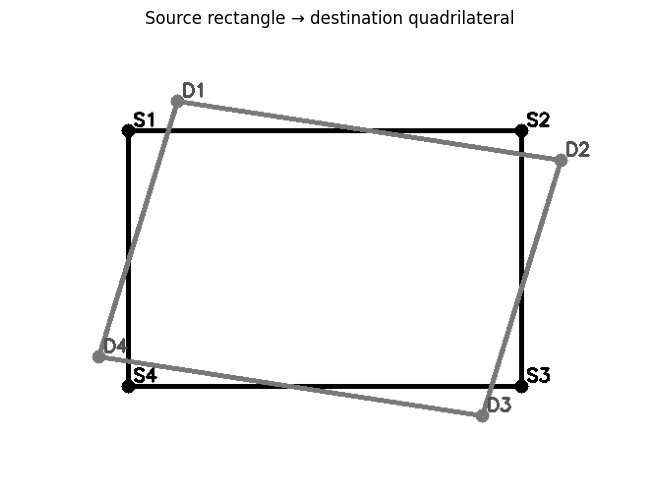

In [14]:
# Draw the source and destination quadrilaterals for visualization.

canvas = np.ones((470, 650, 3), dtype=np.uint8) * 255

src_int = src.astype(int)
dst_int = dst.astype(int)

cv2.polylines(canvas, [src_int], True, (0, 0, 0), 3)
cv2.polylines(canvas, [dst_int], True, (120, 120, 120), 3)

for i, p in enumerate(src_int):
    cv2.circle(canvas, tuple(p), 7, (0, 0, 0), -1)
    cv2.putText(canvas, f"S{i+1}", tuple(p + [5, -5]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

for i, p in enumerate(dst_int):
    cv2.circle(canvas, tuple(p), 7, (120, 120, 120), -1)
    cv2.putText(canvas, f"D{i+1}", tuple(p + [5, -5]),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (80, 80, 80), 2)

plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Source rectangle → destination quadrilateral")
plt.show()

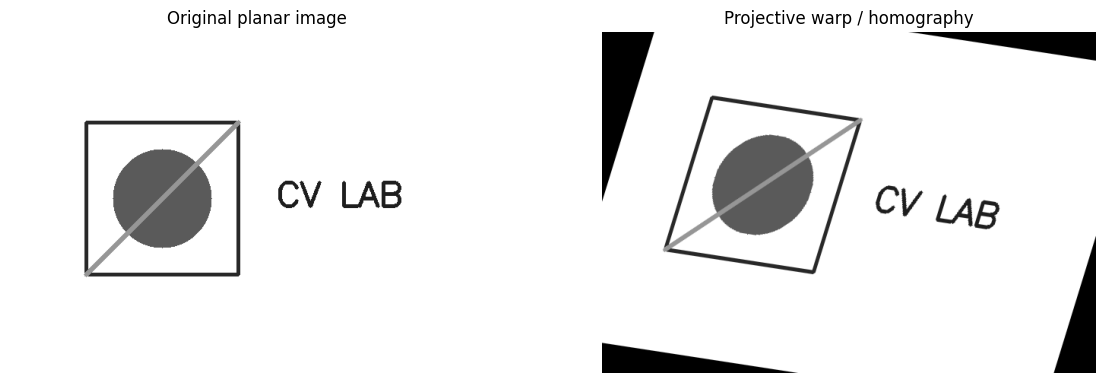

In [15]:
# Apply the homography to the synthetic image.
homography_img = cv2.warpPerspective(img, H, (w, h))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original planar image")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(homography_img, cv2.COLOR_BGR2RGB))
axes[1].set_title("Projective warp / homography")
axes[1].axis("off")

plt.show()

# Part 6 — Transformations using images


Image shape: (297, 392, 3)
Height: 297
Width: 392
Channels: 3


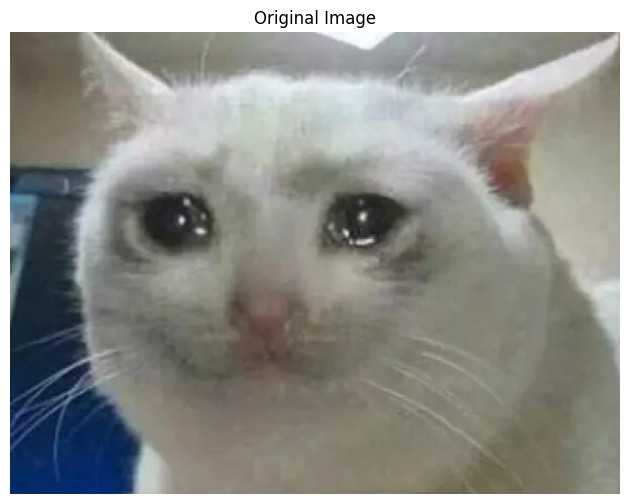

In [27]:
# Change this path to your image
image_path = "cat.png"

# OpenCV loads images in BGR format
img = cv2.imread(image_path)

if img is None:
    raise FileNotFoundError(f"Could not load image: {image_path}")

# Convert BGR -> RGB for matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Image shape:", img.shape)
print("Height:", img.shape[0])
print("Width:", img.shape[1])
print("Channels:", img.shape[2])

plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

## Linear Transformation: Scaling


Original size: 392 × 297
Scaled up size: 588 × 446
Scaled down size: 196 × 148


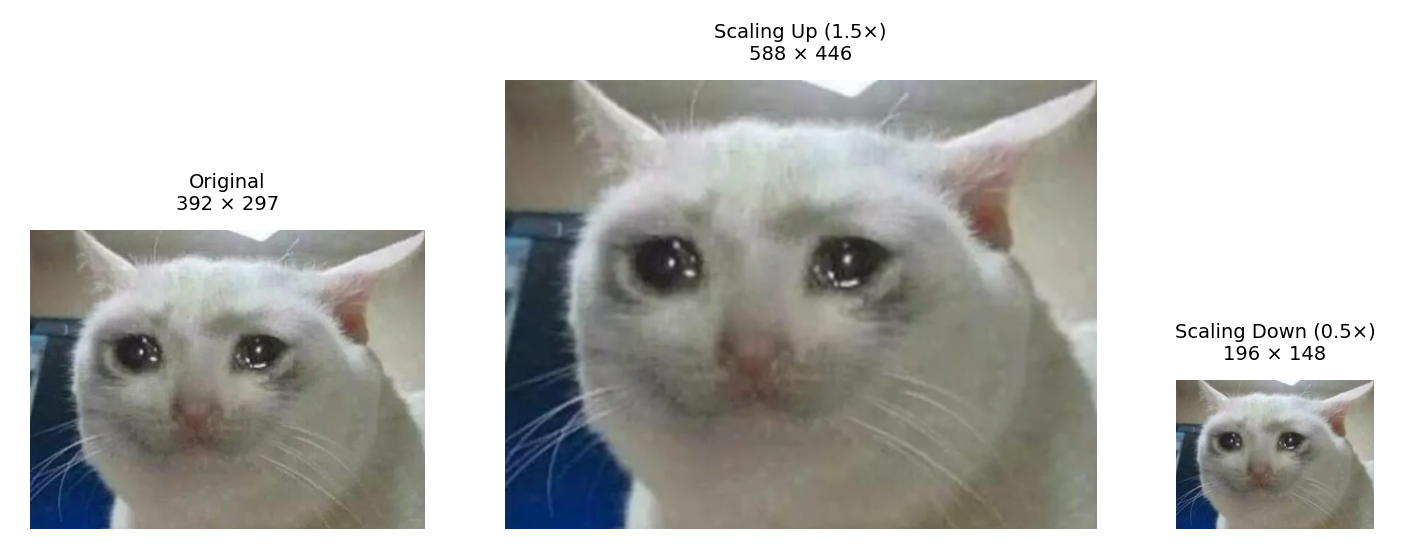

In [28]:
# ============================
# SCALING
# ============================

# Scale up by 1.5×
scaled_up = cv2.resize(
    img_rgb,
    None,
    fx=1.5,
    fy=1.5,
    interpolation=cv2.INTER_LINEAR
)

# Scale down by 0.5×
scaled_down = cv2.resize(
    img_rgb,
    None,
    fx=0.5,
    fy=0.5,
    interpolation=cv2.INTER_AREA
)

# Get dimensions
h, w = img_rgb.shape[:2]
up_h, up_w = scaled_up.shape[:2]
down_h, down_w = scaled_down.shape[:2]

print("Original size:", w, "×", h)
print("Scaled up size:", up_w, "×", up_h)
print("Scaled down size:", down_w, "×", down_h)


# ============================
# DISPLAY AT ACTUAL RELATIVE SIZES
# ============================

fig, ax = plt.subplots(figsize=(18, 7))

# Position of each image
x1 = 0
x2 = w + 80
x3 = x2 + up_w + 80

# Display images using their actual dimensions
ax.imshow(
    img_rgb,
    extent=[x1, x1 + w, 0, h]
)

ax.imshow(
    scaled_up,
    extent=[x2, x2 + up_w, 0, up_h]
)

ax.imshow(
    scaled_down,
    extent=[x3, x3 + down_w, 0, down_h]
)

# Titles
ax.text(
    x1 + w/2,
    h + 20,
    f"Original\n{w} × {h}",
    ha="center",
    fontsize=14
)

ax.text(
    x2 + up_w/2,
    up_h + 20,
    f"Scaling Up (1.5×)\n{up_w} × {up_h}",
    ha="center",
    fontsize=14
)

ax.text(
    x3 + down_w/2,
    down_h + 20,
    f"Scaling Down (0.5×)\n{down_w} × {down_h}",
    ha="center",
    fontsize=14
)

# Make sure the actual proportions are preserved
ax.set_aspect("equal")

# Remove axes
ax.axis("off")

# Set limits so all images are visible
ax.set_xlim(-20, x3 + down_w + 20)
ax.set_ylim(-20, up_h + 70)

plt.show()

## Linear Transformation: Rotation




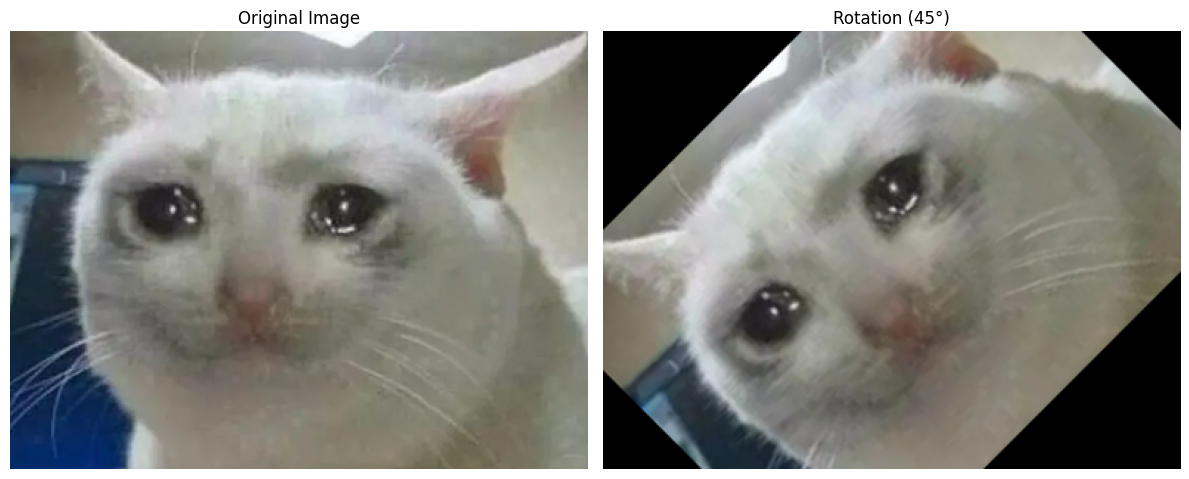

In [29]:
# ============================
# ROTATION
# ============================

# Get image dimensions
h, w = img_rgb.shape[:2]

# Rotation angle
angle = 45

# Rotation matrix
center = (w // 2, h // 2)

M = cv2.getRotationMatrix2D(
    center,
    angle,
    1.0
)

# Rotate the image
rotated = cv2.warpAffine(
    img_rgb,
    M,
    (w, h)
)

# ============================
# DISPLAY
# ============================

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rotated)
plt.title("Rotation (45°)")
plt.axis("off")

plt.tight_layout()
plt.show()

## Affine Transformation: Rotation + Translation

Affine Transformation Matrix:
[[  0.866   0.5    52.259]
 [ -0.5     0.866 167.828]]


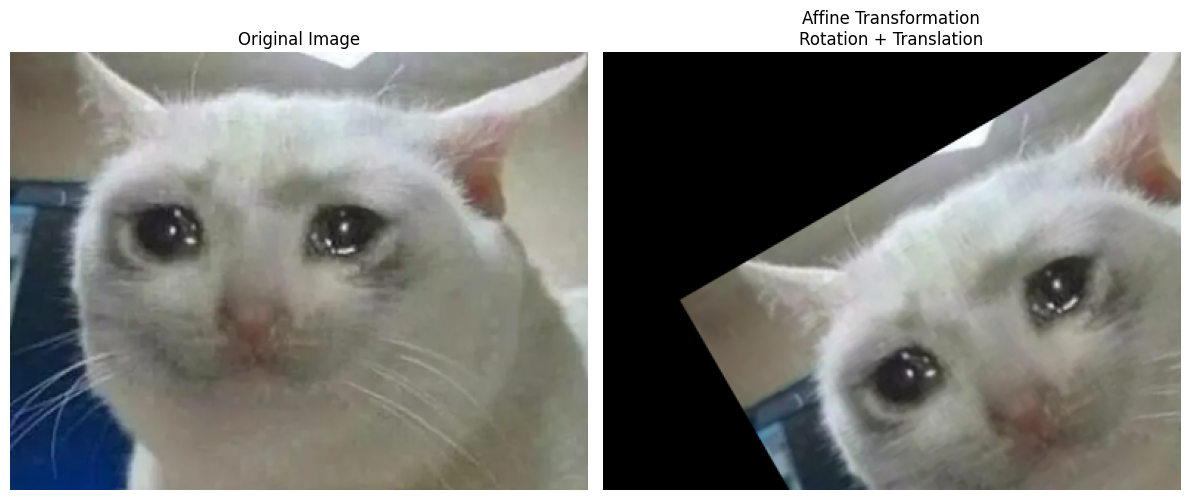

In [31]:
# ============================================================
# AFFINE TRANSFORMATION
# Rotation + Scaling + Translation
# ============================================================

# Get image dimensions
h, w = img_rgb.shape[:2]

# ------------------------------------------------------------
# Define affine transformation
# ------------------------------------------------------------

# Rotation angle
angle = 30

# Scaling factor
scale = 1.0 # Since it is 1, so no scaling!

# Translation
tx = 100
ty = 50

# Create rotation + scaling matrix
M = cv2.getRotationMatrix2D(
    (w // 2, h // 2),
    angle,
    scale
)

# Add translation to the affine matrix
M[0, 2] += tx
M[1, 2] += ty

print("Affine Transformation Matrix:")
print(M)

# ------------------------------------------------------------
# Apply affine transformation
# ------------------------------------------------------------

transformed = cv2.warpAffine(
    img_rgb,
    M,
    (w, h)
)

# ============================================================
# DISPLAY
# ============================================================

plt.figure(figsize=(12, 6))

# Original
plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

# Affine transformed
plt.subplot(1, 2, 2)
plt.imshow(transformed)
plt.title("Affine Transformation\nRotation + Translation")
plt.axis("off")

plt.tight_layout()
plt.show()